# Lab 3: Exploratory Data Analysis (EDA)

**Name:** Yashodhara Heggade  
**Reg:** 2427010154  
**Sec:** C/ Batch 1

## Objective
Perform descriptive statistics and explore a dataset using histograms, a scatter plot, box plots, a correlation heatmap, and pair plots.

## Dataset: Kaggle Titanic - Machine Learning from Disaster


## 1. Import libraries

Pandas organizes the data. Matplotlib and Seaborn create the visualizations. `Path` helps locate the downloaded CSV file.

In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Load and inspect the Kaggle data


In [6]:
# Look in common Kaggle Notebook and local locations
csv_candidates = [
    Path("/kaggle/input/titanic/train.csv"),
    Path("train.csv"),
    Path("data/train.csv")
]
csv_path = next((path for path in csv_candidates if path.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find train.csv. Download it from the Kaggle Titanic competition page "
        "and put it beside this notebook (or in ./data/train.csv). On Kaggle, attach "
        "the Titanic dataset so it is available under /kaggle/input/titanic/."
    )

df = pd.read_csv(csv_path)
print("Loaded file:", csv_path)
print("Dataset shape (rows, columns):", df.shape)
df.head()

Loaded file: train.csv
Dataset shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
# Inspect data types and missing values
print("Column data types:")
print(df.dtypes)
print("\nMissing values in each column:")
print(df.isnull().sum())

Column data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


## 3. Descriptive statistics


In [8]:
# Summary statistics for numerical columns
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
# Summary statistics for both numerical and categorical columns
df.describe(include="all")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [10]:
# Compare survival counts and survival rate
print("Survival counts (0 = did not survive, 1 = survived):")
print(df["Survived"].value_counts().sort_index())
print("\nSurvival rate:")
print(df["Survived"].mean().round(3))

Survival counts (0 = did not survive, 1 = survived):
Survived
0    549
1    342
Name: count, dtype: int64

Survival rate:
0.384


## 4. Histograms


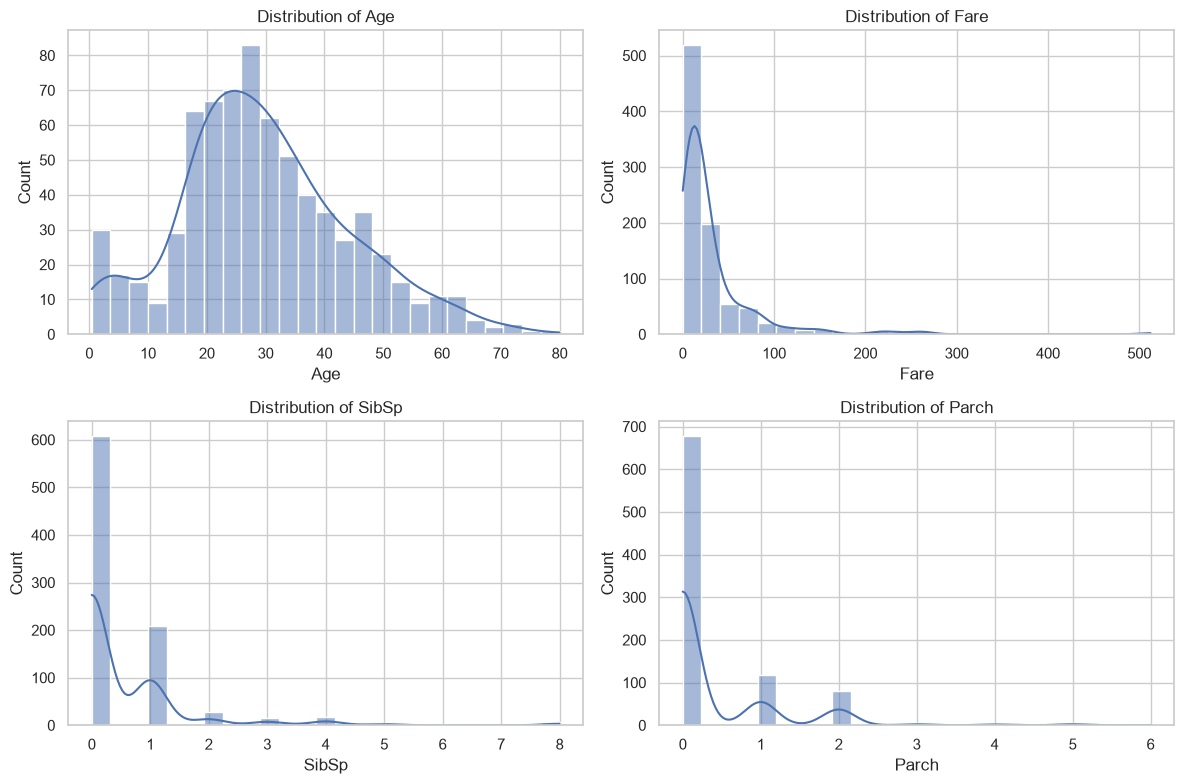

In [11]:
numeric_features = ["Age", "Fare", "SibSp", "Parch"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for index, feature in enumerate(numeric_features):
    sns.histplot(data=df, x=feature, bins=25, kde=True, ax=axes[index])
    axes[index].set_title(f"Distribution of {feature}")
plt.tight_layout()
plt.show()

## 5. Scatter plot


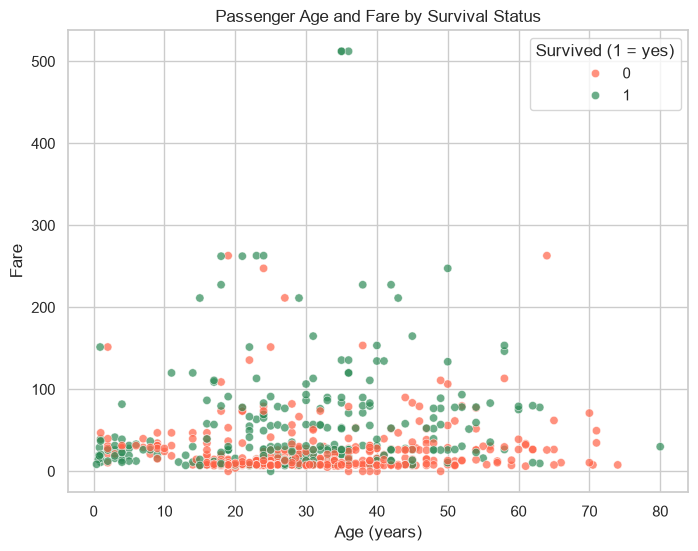

In [12]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, x="Age", y="Fare", hue="Survived",
    palette={0: "tomato", 1: "seagreen"}, alpha=0.7
)
plt.title("Passenger Age and Fare by Survival Status")
plt.xlabel("Age (years)")
plt.ylabel("Fare")
plt.legend(title="Survived (1 = yes)")
plt.show()

## 6. Box plots



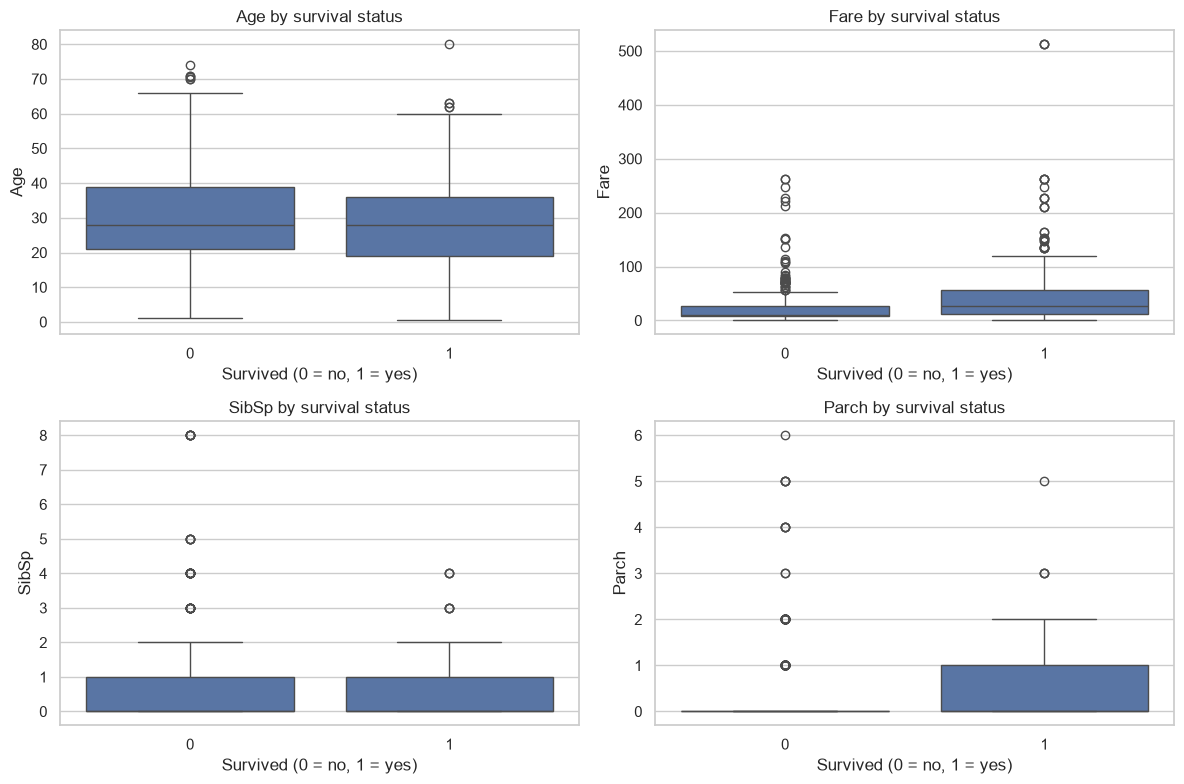

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for index, feature in enumerate(numeric_features):
    sns.boxplot(data=df, x="Survived", y=feature, ax=axes[index])
    axes[index].set_title(f"{feature} by survival status")
    axes[index].set_xlabel("Survived (0 = no, 1 = yes)")
plt.tight_layout()
plt.show()

## 7. Correlation heatmap

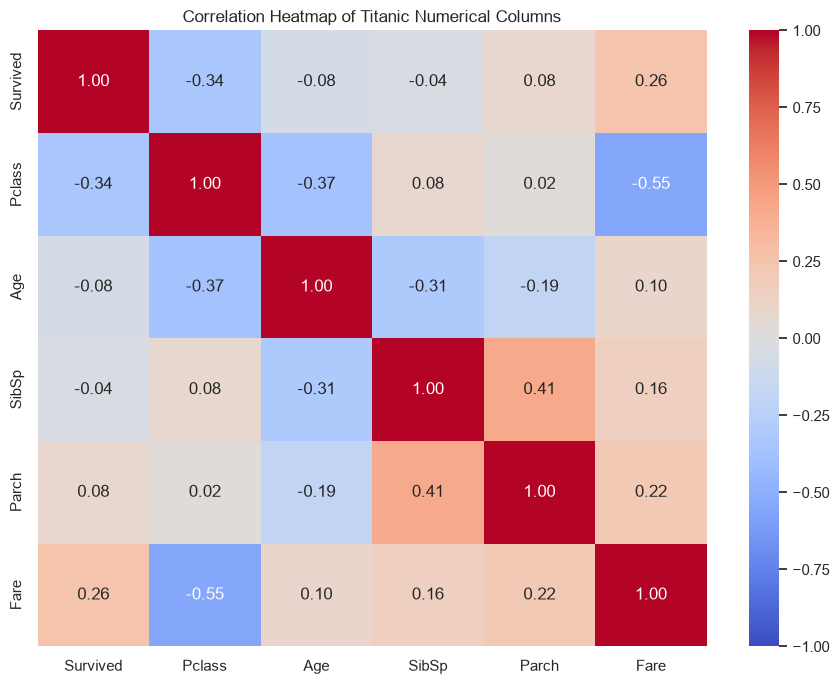

In [14]:
correlation_columns = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix, annot=True, cmap="coolwarm",
    fmt=".2f", vmin=-1, vmax=1
)
plt.title("Correlation Heatmap of Titanic Numerical Columns")
plt.tight_layout()
plt.show()

## 8. Pair plot


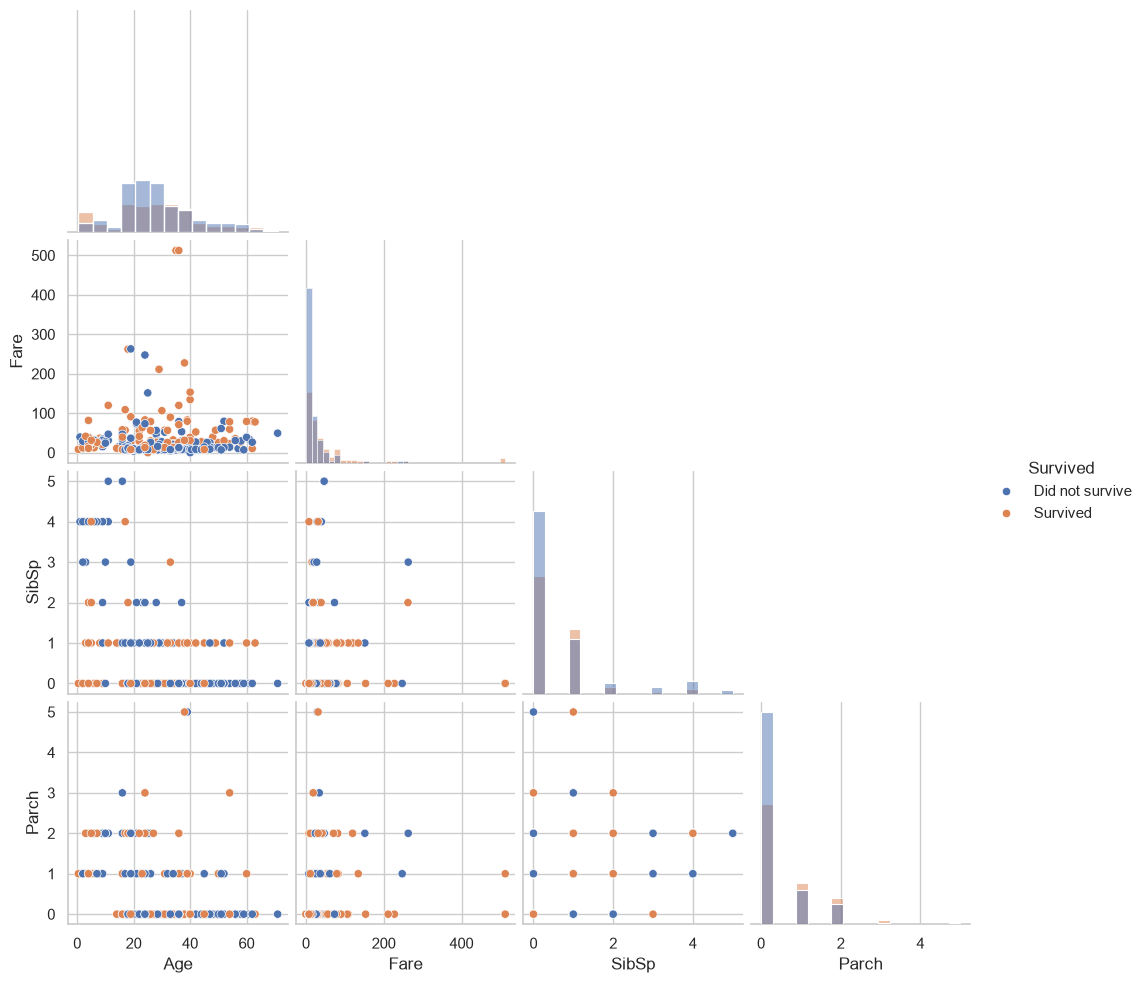

In [15]:
pairplot_data = df[["Age", "Fare", "SibSp", "Parch", "Survived"]].dropna()
pairplot_data["Survived"] = pairplot_data["Survived"].map({0: "Did not survive", 1: "Survived"})

sns.pairplot(
    pairplot_data.sample(n=min(300, len(pairplot_data)), random_state=42),
    hue="Survived", diag_kind="hist", corner=True
)
plt.show()